<a href="https://colab.research.google.com/github/JantikarShobith/BIS_LAB/blob/main/1BM24CS351_Week4_CuckooSearch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Cuckoo Search for Robot Navigation...

Iteration   1 | Best Path Cost: 1046.62
Iteration  30 | Best Path Cost: 533.64
Iteration  60 | Best Path Cost: 533.57
Iteration  90 | Best Path Cost: 533.56
Iteration 120 | Best Path Cost: 533.56
Iteration 150 | Best Path Cost: 533.56

          ROBOT NAVIGATION RESULTS              
 Optimal Path Cost  : 533.56
 Waypoint Coordinates (x, y):
  [START ] -> ( 1.00,  1.00)
  [WP 1  ] -> ( 2.53,  1.83)
  [WP 2  ] -> ( 7.51,  4.53)
  [WP 3  ] -> ( 9.43,  3.49)
  [WP 4  ] -> (13.82,  1.06)
  [WP 5  ] -> (17.09,  2.75)
  [TARGET] -> (18.00, 18.00)


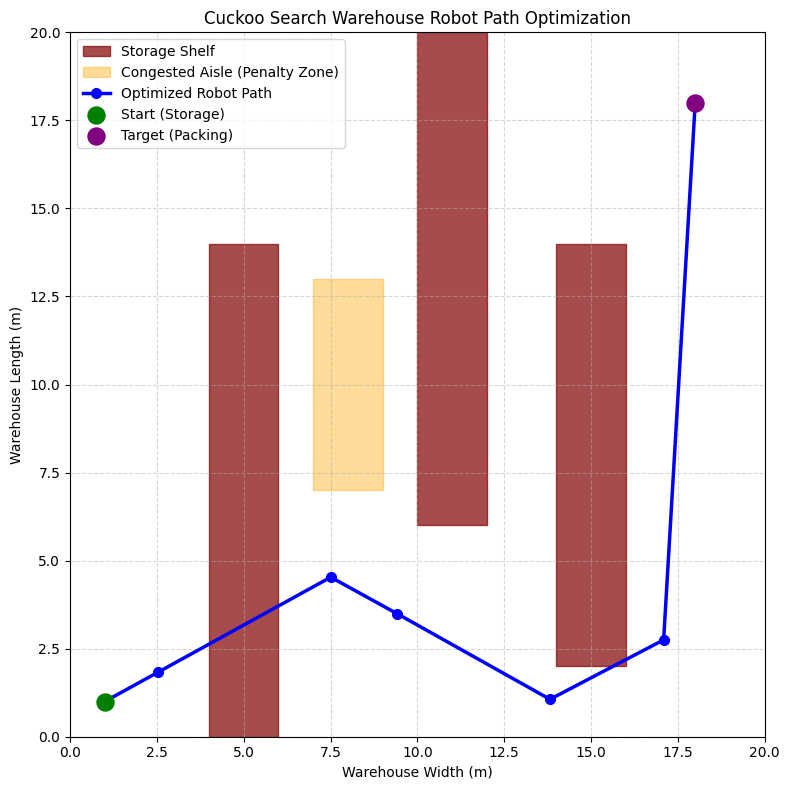

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sc_special


GRID_SIZE = 20
START_POS = np.array([1.0, 1.0])
TARGET_POS = np.array([18.0, 18.0])
NUM_WAYPOINTS = 5


OBSTACLES = [
    np.array([4.0, 0.0, 6.0, 14.0]),
    np.array([10.0, 6.0, 12.0, 20.0]),
    np.array([14.0, 2.0, 16.0, 14.0])
]


CONGESTED_ZONE = np.array([7.0, 7.0, 9.0, 13.0, 3.0])


NUM_NESTS = 25
MAX_ITER = 150
PA = 0.25
LAMBDA = 1.5



def reconstruct_path(waypoints):
    """Reconstructs full path array including fixed start and target."""
    pts = waypoints.reshape(NUM_WAYPOINTS, 2)
    return np.vstack([START_POS, pts, TARGET_POS])

def is_point_in_box(pt, box):
    return (box[0] <= pt[0] <= box[2]) and (box[1] <= pt[1] <= box[3])

def line_intersects_box(p1, p2, box, num_samples=10):
    """Checks segment-box intersection via fine line-sampling."""
    for t in np.linspace(0, 1, num_samples):
        sample = p1 + t * (p2 - p1)
        if is_point_in_box(sample, box):
            return True
    return False

def evaluate_fitness(waypoints):
    """
    Computes total path cost:
    Cost = Path Length + Obstacle Penalty + Congestion Penalty
    """
    path = reconstruct_path(waypoints)
    total_length = 0.0
    penalty = 0.0

    for i in range(len(path) - 1):
        p1, p2 = path[i], path[i+1]
        segment_len = np.linalg.norm(p2 - p1)
        total_length += segment_len

        # Check collision with Storage Shelves
        for obs in OBSTACLES:
            if line_intersects_box(p1, p2, obs):
                penalty += 500.0  # Heavy collision penalty

        # Check traversal through Congested Aisles
        if line_intersects_box(p1, p2, CONGESTED_ZONE[:4]):
            penalty += segment_len * CONGESTED_ZONE[4]  # Time-delay factor

    return total_length + penalty



def levy_flight(size, alpha=0.5):
    """Generates random step vectors using Mantegna's algorithm for Lévy distribution."""
    num = sc_special.gamma(1 + LAMBDA) * np.sin(np.pi * LAMBDA / 2)
    den = sc_special.gamma((1 + LAMBDA) / 2) * LAMBDA * (2**((LAMBDA - 1) / 2))
    sigma = (num / den)**(1 / LAMBDA)

    u = np.random.normal(0, sigma, size=size)
    v = np.random.normal(0, 1, size=size)
    step = u / (np.abs(v)**(1 / LAMBDA))

    return alpha * step



def run_cuckoo_search():
    np.random.seed(42)
    dim = NUM_WAYPOINTS * 2


    nests = np.random.uniform(0.0, GRID_SIZE, size=(NUM_NESTS, dim))
    fitness = np.array([evaluate_fitness(n) for n in nests])


    best_idx = np.argmin(fitness)
    best_nest = nests[best_idx].copy()
    best_fitness = fitness[best_idx]

    print("Starting Cuckoo Search for Robot Navigation...\n")

    for it in range(MAX_ITER):

        for i in range(NUM_NESTS):
            step_size = levy_flight(dim)
            new_nest = nests[i] + step_size * (nests[i] - best_nest)
            new_nest = np.clip(new_nest, 0.0, GRID_SIZE)  # Boundary constraint

            f_new = evaluate_fitness(new_nest)


            j = np.random.randint(0, NUM_NESTS)
            if f_new < fitness[j]:
                nests[j] = new_nest
                fitness[j] = f_new

        # --- Step B: Host Bird Discovery (Abandonment of worst paths) ---
        random_nests_1 = nests[np.random.permutation(NUM_NESTS)]
        random_nests_2 = nests[np.random.permutation(NUM_NESTS)]

        K = np.random.uniform(0, 1, size=nests.shape) < PA
        step_rand = np.random.uniform(0, 1, size=nests.shape) * (random_nests_1 - random_nests_2)

        nests_abandoned = nests + K * step_rand
        nests_abandoned = np.clip(nests_abandoned, 0.0, GRID_SIZE)

        # Update nests if abandoned solutions are better
        for i in range(NUM_NESTS):
            f_abandoned = evaluate_fitness(nests_abandoned[i])
            if f_abandoned < fitness[i]:
                nests[i] = nests_abandoned[i]
                fitness[i] = f_abandoned

        # --- Step C: Update Global Best ---
        current_best_idx = np.argmin(fitness)
        if fitness[current_best_idx] < best_fitness:
            best_fitness = fitness[current_best_idx]
            best_nest = nests[current_best_idx].copy()

        if (it + 1) % 30 == 0 or it == 0:
            print(f"Iteration {it+1:3d} | Best Path Cost: {best_fitness:.2f}")

    return best_nest, best_fitness



best_waypoints, min_cost = run_cuckoo_search()
optimal_path = reconstruct_path(best_waypoints)

print("\n=================================================")
print("          ROBOT NAVIGATION RESULTS              ")
print("=================================================")
print(f" Optimal Path Cost  : {min_cost:.2f}")
print(" Waypoint Coordinates (x, y):")
for idx, pt in enumerate(optimal_path):
    label = "START" if idx == 0 else ("TARGET" if idx == len(optimal_path)-1 else f"WP {idx}")
    print(f"  [{label:6s}] -> ({pt[0]:5.2f}, {pt[1]:5.2f})")
print("=================================================")

# Plotting the Warehouse Grid
fig, ax = plt.subplots(figsize=(8, 8))

# Draw Shelves (Obstacles)
for obs in OBSTACLES:
    rect = plt.Rectangle((obs[0], obs[1]), obs[2]-obs[0], obs[3]-obs[1],
                         color='maroon', alpha=0.7, label='Storage Shelf')
    ax.add_patch(rect)

# Draw Congested Aisle Zone
cz = CONGESTED_ZONE
rect_cz = plt.Rectangle((cz[0], cz[1]), cz[2]-cz[0], cz[3]-cz[1],
                        color='orange', alpha=0.4, label='Congested Aisle (Penalty Zone)')
ax.add_patch(rect_cz)

# Plot Path
ax.plot(optimal_path[:, 0], optimal_path[:, 1], 'b-o', linewidth=2.5, markersize=7, label='Optimized Robot Path')
ax.scatter([START_POS[0]], [START_POS[1]], color='green', s=150, zorder=5, label='Start (Storage)')
ax.scatter([TARGET_POS[0]], [TARGET_POS[1]], color='purple', s=150, zorder=5, label='Target (Packing)')

# Avoid duplicate legend entries
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper left')

ax.set_xlim(0, GRID_SIZE)
ax.set_ylim(0, GRID_SIZE)
ax.set_xlabel("Warehouse Width (m)")
ax.set_ylabel("Warehouse Length (m)")
ax.set_title("Cuckoo Search Warehouse Robot Path Optimization")
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()